# Лабораторная работа: модель векторизации в задаче мультиклассовой классификации текстов

**Цель:** обучить классификатор поверх модели энкодера и сравнить две стратегии пулинга токенных эмбеддингов в один вектор текста - `mean_pooling` и `cls_pooling`.

**Как устроен эксперимент**

```
текст → токенизатор → энкодер → [h_1 … h_n] → пулинг → вектор текста → Dropout → Linear → логиты 6 классов
```

* `mean_pooling` - среднее токенных эмбеддингов с учётом `attention_mask` (паддинг не учитывается);
* `cls_pooling` - эмбеддинг служебного токена `[CLS]` (`last_hidden_state[:, 0]`).

Для каждого пулинга запускаются оба режима:

* **A. Fine-tuning (основной)** - обучаются энкодер и голова целиком;
* **B. Frozen encoder (дополнительный)** - энкодер заморожен, на готовых эмбеддингах обучается только линейный классификатор (softmax-регрессия с L2-регуляризацией).

Так как разница между пулингами, скорее всего, небольшая, fine-tuning повторяется на нескольких сидах: сравниваем средние ± стандартное отклонение, а не одиночные запуски.

In [ ]:
import os, json, random, time, functools
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from torch.utils.data import DataLoader
from IPython.display import display

import datasets as hf_datasets
import transformers
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModel, DataCollatorWithPadding, get_linear_schedule_with_warmup
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

hf_datasets.disable_progress_bars()
transformers.utils.logging.set_verbosity_error()
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

device: cuda | NVIDIA GeForce RTX 3070 Ti


## Конфигурация

Все гиперпараметры - в одном месте и одинаковые для обоих пулингов

In [ ]:
DATASET, DATASET_CONFIG = "dair-ai/emotion", "split"
MODEL_NAME = "BAAI/bge-small-en-v1.5"

MAX_LEN = 64            # p99 длины в токенах ≈ 57, максимум ≈ 71
BATCH_SIZE = 32
EPOCHS = 3
LR_ENCODER = 5e-5
LR_HEAD = 1e-3
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
DROPOUT = 0.1
SEEDS = [0, 1, 2, 3, 4]
POOLINGS = ["mean", "cls"]

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)
CACHE_PATH = os.path.join(RESULTS_DIR, "runs.json")   # кэш запусков: повторный прогон ноутбука не переобучает модели


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

## 1. Выбор датасета

**[`dair-ai/emotion`](https://huggingface.co/datasets/dair-ai/emotion)** - короткие англоязычные сообщения из Twitter, размеченные на 6 эмоций: `sadness, joy, love, anger, fear, surprise`.

Почему он подходит:
*  **мультиклассовая** задача (6 классов, у каждого текста ровно одна метка);
* **классы несбалансированы** (от 572 до 5362 примеров), поэтому `accuracy` недостаточно, а `macro`-метрики показывают качество на редких классах (`surprise`, `love`);
* готовое разбиение train / validation / test (16 000 / 2 000 / 2 000) и небольшой размер - можно сделать много прогонов на одной видеокарте.

Валидационная выборка используется для выбора эпохи, тестовая - только для итоговых метрик.

In [ ]:
ds = load_dataset(DATASET, DATASET_CONFIG)
class_names = ds["train"].features["label"].names
N_CLASSES = len(class_names)

dist = pd.DataFrame({
    split: pd.Series(ds[split]["label"]).map(dict(enumerate(class_names))).value_counts()
    for split in ["train", "validation", "test"]
}).loc[class_names]
dist["train, %"] = (100 * dist["train"] / dist["train"].sum()).round(1)
display(dist)

for i in range(3):
    print(f"[{class_names[ds['train'][i]['label']]:>8}]  {ds['train'][i]['text']}")

,train,validation,test,"train, %"
sadness,4666,550,581,29.2
joy,5362,704,695,33.5
love,1304,178,159,8.2
anger,2159,275,275,13.5
fear,1937,212,224,12.1
surprise,572,81,66,3.6


[ sadness]  i didnt feel humiliated
[ sadness]  i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake
[   anger]  im grabbing a minute to post i feel greedy wrong


## 2. Выбор модели векторизации

**[`BAAI/bge-small-en-v1.5`](https://huggingface.co/BAAI/bge-small-en-v1.5)** - компактный BERT-подобный энкодер (≈33M параметров, 12 слоёв, эмбеддинг размерности 384), специально обученный для получения векторных представлений текстов.

Почему именно он:
* небольшой размер - fine-tuning на 8 ГБ видеокарты занимает около минуты на запуск;
* модель **обучалась с `[CLS]`-пулингом** (так её рекомендует использовать автор), поэтому интересно проверить, сохранится ли это преимущество у `cls_pooling` на нашей задаче и как себя покажет `mean_pooling`, для которого модель напрямую не обучалась.

Замечание: `AutoModel` для BERT содержит ещё слой `pooler` (Linear + tanh над `[CLS]`). Мы его **не используем** - пулинг реализуем сами над `last_hidden_state`, чтобы обе стратегии были абсолютно прозрачны.

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)


tok_ds = ds.map(tokenize, batched=True, remove_columns=["text"]).rename_column("label", "labels")
collator = DataCollatorWithPadding(tokenizer)

val_dl = DataLoader(tok_ds["validation"], batch_size=128, collate_fn=collator)
test_dl = DataLoader(tok_ds["test"], batch_size=128, collate_fn=collator)

print(tok_ds)

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2000
    })
})


## Общий код: пулинг, модель, обучение, метрики

In [ ]:
def mean_pooling(hidden, attention_mask):
    """Среднее по реальным токенам (паддинг маскируется)."""
    mask = attention_mask.unsqueeze(-1).to(hidden.dtype)
    return (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)


def cls_pooling(hidden, attention_mask):
    """Эмбеддинг первого токена [CLS]."""
    return hidden[:, 0]


POOLING_FNS = {"mean": mean_pooling, "cls": cls_pooling}


class PoolingClassifier(nn.Module):
    def __init__(self, model_name, pooling, n_classes, dropout=DROPOUT):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        self.pool = POOLING_FNS[pooling]
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(self.encoder.config.hidden_size, n_classes)

    def forward(self, input_ids, attention_mask):
        hidden = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        return self.head(self.dropout(self.pool(hidden.float(), attention_mask)))


def compute_metrics(y_true, y_pred):
    """Accuracy + Precision/Recall/F1 в macro- и weighted-усреднении."""
    out = {"accuracy": accuracy_score(y_true, y_pred)}
    for avg in ("macro", "weighted"):
        p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average=avg, zero_division=0)
        out.update({f"precision_{avg}": p, f"recall_{avg}": r, f"f1_{avg}": f})
    return {k: float(v) for k, v in out.items()}


@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, labels = [], []
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device.type, dtype=torch.bfloat16, enabled=device.type == "cuda"):
            logits = model(batch["input_ids"], batch["attention_mask"])
        preds.append(logits.argmax(-1).cpu())
        labels.append(batch["labels"].cpu())
    return torch.cat(labels).numpy(), torch.cat(preds).numpy()


def per_class_and_confusion(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=range(N_CLASSES), zero_division=0)
    return ({"precision": p.tolist(), "recall": r.tolist(), "f1": f.tolist()},
            confusion_matrix(y_true, y_pred, labels=range(N_CLASSES)).tolist())


def run_finetune(pooling, seed):
    """Режим A: обучаем энкодер и голову целиком. Эпоха выбирается по val macro-F1."""
    set_seed(seed)
    model = PoolingClassifier(MODEL_NAME, pooling, N_CLASSES).to(device)
    gen = torch.Generator().manual_seed(seed)
    train_dl = DataLoader(tok_ds["train"], batch_size=BATCH_SIZE, shuffle=True, collate_fn=collator, generator=gen)

    optimizer = torch.optim.AdamW([
        {"params": model.encoder.parameters(), "lr": LR_ENCODER},
        {"params": model.head.parameters(), "lr": LR_HEAD},
    ], weight_decay=WEIGHT_DECAY)
    total_steps = EPOCHS * len(train_dl)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)
    loss_fn = nn.CrossEntropyLoss()

    history, t0 = [], time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        losses = []
        for batch in train_dl:
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.autocast(device.type, dtype=torch.bfloat16, enabled=device.type == "cuda"):
                logits = model(batch["input_ids"], batch["attention_mask"])
            loss = loss_fn(logits.float(), batch["labels"])
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            losses.append(loss.item())

        y_val, p_val = predict(model, val_dl)
        y_test, p_test = predict(model, test_dl)
        history.append({"epoch": epoch, "train_loss": float(np.mean(losses)),
                        "val": compute_metrics(y_val, p_val), "test": compute_metrics(y_test, p_test),
                        "test_pred": p_test.tolist()})
        print(f"  [{pooling} | seed {seed}] epoch {epoch}: loss {history[-1]['train_loss']:.4f} | "
              f"val F1 {history[-1]['val']['f1_macro']:.4f} | test F1 {history[-1]['test']['f1_macro']:.4f}")

    best = max(history, key=lambda h: h["val"]["f1_macro"])
    per_class, conf = per_class_and_confusion(y_test, np.array(best["test_pred"]))
    for h in history:
        h.pop("test_pred")
    del model, optimizer
    torch.cuda.empty_cache()
    return {"mode": "finetune", "pooling": pooling, "seed": seed, "best_epoch": best["epoch"],
            "history": history, "val": best["val"], "test": best["test"],
            "per_class": per_class, "confusion": conf, "seconds": time.time() - t0}


@functools.lru_cache(maxsize=None)
def frozen_features():
    """Эмбеддинги исходной (не дообученной) модели: за один проход считаем оба пулинга."""
    encoder = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()
    feats = {}
    for split in ["train", "validation", "test"]:
        loader = DataLoader(tok_ds[split], batch_size=256, collate_fn=collator)
        buf = {p: [] for p in POOLINGS}
        labels = []
        with torch.no_grad():
            for batch in loader:
                batch = {k: v.to(device) for k, v in batch.items()}
                with torch.autocast(device.type, dtype=torch.bfloat16, enabled=device.type == "cuda"):
                    hidden = encoder(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).last_hidden_state
                for p in POOLINGS:
                    buf[p].append(POOLING_FNS[p](hidden.float(), batch["attention_mask"]).cpu())
                labels.append(batch["labels"].cpu())
        feats[split] = ({p: torch.cat(buf[p]).numpy() for p in POOLINGS}, torch.cat(labels).numpy())
    del encoder
    torch.cuda.empty_cache()
    return feats


def fit_softmax_regression(x, y, l2):
    """Линейный классификатор (softmax-регрессия) с L2-регуляризацией, полный батч, LBFGS на GPU."""
    x = torch.as_tensor(x, dtype=torch.float32, device=device)
    y = torch.as_tensor(y, dtype=torch.long, device=device)
    linear = nn.Linear(x.shape[1], N_CLASSES).to(device)
    optimizer = torch.optim.LBFGS(linear.parameters(), lr=1.0, max_iter=500, history_size=20,
                                  line_search_fn="strong_wolfe")

    def closure():
        optimizer.zero_grad()
        loss = nn.functional.cross_entropy(linear(x), y) + l2 * linear.weight.pow(2).sum()
        loss.backward()
        return loss

    optimizer.step(closure)
    return lambda z: linear(torch.as_tensor(z, dtype=torch.float32, device=device)).argmax(-1).cpu().numpy()


def run_frozen(pooling, seed=0):
    """Режим B: энкодер заморожен, линейный классификатор на эмбеддингах.
    Коэффициент L2-регуляризации подбирается по val macro-F1."""
    feats = frozen_features()
    (x_tr, y_tr), (x_va, y_va), (x_te, y_te) = [(feats[s][0][pooling], feats[s][1]) for s in ("train", "validation", "test")]
    scaler = StandardScaler().fit(x_tr)
    x_tr, x_va, x_te = scaler.transform(x_tr), scaler.transform(x_va), scaler.transform(x_te)

    t0, best = time.time(), None
    for l2 in [1e-6, 1e-5, 1e-4, 1e-3, 1e-2]:
        predict_fn = fit_softmax_regression(x_tr, y_tr, l2)
        val = compute_metrics(y_va, predict_fn(x_va))
        if best is None or val["f1_macro"] > best[0]["f1_macro"]:
            best = (val, l2, predict_fn)
    val, l2, predict_fn = best
    p_test = predict_fn(x_te)
    per_class, conf = per_class_and_confusion(y_te, p_test)
    print(f"  [{pooling} | frozen] l2={l2:g}: val F1 {val['f1_macro']:.4f} | test F1 {compute_metrics(y_te, p_test)['f1_macro']:.4f}")
    return {"mode": "frozen", "pooling": pooling, "seed": seed, "l2": l2, "val": val,
            "test": compute_metrics(y_te, p_test), "per_class": per_class, "confusion": conf,
            "seconds": time.time() - t0}


def get_run(mode, pooling, seed=0):
    """Возвращает результат запуска из кэша либо запускает обучение и сохраняет результат."""
    cache = json.load(open(CACHE_PATH, encoding="utf-8")) if os.path.exists(CACHE_PATH) else {}
    key = f"{mode}|{pooling}|{seed}"
    if key not in cache:
        cache[key] = run_finetune(pooling, seed) if mode == "finetune" else run_frozen(pooling, seed)
        json.dump(cache, open(CACHE_PATH, "w", encoding="utf-8"), ensure_ascii=False)
    return cache[key]


METRICS = ["precision_macro", "recall_macro", "f1_macro", "precision_weighted", "recall_weighted", "f1_weighted", "accuracy"]


def runs_table(mode, pooling):
    """Метрики на test по сидам + строки mean/std."""
    seeds = SEEDS if mode == "finetune" else [0]
    df = pd.DataFrame([get_run(mode, pooling, s)["test"] for s in seeds], index=[f"seed {s}" for s in seeds])[METRICS]
    if len(df) > 1:
        df.loc["mean"] = df.mean()
        df.loc["std"] = df.iloc[:-1].std(ddof=1)
    return df


def show_report(mode, pooling, seed=0):
    """Метрики по классам для одного запуска (по сути sklearn.classification_report)."""
    run = get_run(mode, pooling, seed)
    pc = run["per_class"]
    support = np.array(run["confusion"]).sum(axis=1)
    return pd.DataFrame({"precision": pc["precision"], "recall": pc["recall"], "f1": pc["f1"], "support": support},
                        index=class_names).round(4)

## 3. Классификатор с `mean_pooling`

**A. Fine-tuning** - 5 сидов, по 3 эпохи. Одинаковый сид означает одинаковую инициализацию головы и порядок батчей, поэтому запуски `mean` и `cls` с одним сидом отличаются только пулингом это и позволит сделать парное сравнение.

**B. Frozen encoder** - линейный классификатор на готовых усреднённых эмбеддингах.

In [ ]:
for seed in SEEDS:
    get_run("finetune", "mean", seed)
get_run("frozen", "mean")

## 4. Метрики: `mean_pooling`

Основные метрики для несбалансированной многоклассовой задачи - **macro** (каждый класс весит одинаково); **weighted** взвешивает по числу примеров класса. Все значения - на **тестовой** выборке, эпоха выбрана по валидационной.

In [ ]:
print("A. Fine-tuning, mean_pooling")
mean_ft = runs_table("finetune", "mean")
display(mean_ft.round(4))
print("\nМетрики по классам (fine-tuning, seed 0):")
display(show_report("finetune", "mean", 0))

print("\nB. Frozen encoder, mean_pooling")
display(runs_table("frozen", "mean").round(4))

A. Fine-tuning, mean_pooling


,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,accuracy
seed 0,0.9289,0.8586,0.8809,0.9332,0.9305,0.9285,0.9305
seed 1,0.8857,0.8877,0.8866,0.9299,0.9295,0.9296,0.9295
seed 2,0.8818,0.9119,0.8920,0.9335,0.9295,0.9303,0.9295
seed 3,0.8956,0.8907,0.8913,0.9319,0.9305,0.9306,0.9305
seed 4,0.8965,0.8908,0.8931,0.9320,0.9320,0.9318,0.9320
mean,0.8977,0.8879,0.8888,0.9321,0.9304,0.9302,0.9304
std,0.0186,0.0190,0.0050,0.0014,0.0010,0.0012,0.0010



Метрики по классам (fine-tuning, seed 0):


,precision,recall,f1,support
sadness,0.9573,0.9656,0.9614,581
joy,0.9399,0.9669,0.9532,695
love,0.8819,0.7987,0.8383,159
anger,0.9567,0.8836,0.9187,275
fear,0.8377,0.9911,0.9080,224
surprise,1.0000,0.5455,0.7059,66



B. Frozen encoder, mean_pooling


,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,accuracy
seed 0,0.6716,0.6386,0.653,0.7178,0.7225,0.7189,0.7225


## 5. Классификатор с `cls_pooling`

Те же сиды, те же гиперпараметры - меняется только функция пулинга.

In [ ]:
for seed in SEEDS:
    get_run("finetune", "cls", seed)
get_run("frozen", "cls");

## 6. Метрики: `cls_pooling`

In [ ]:
print("A. Fine-tuning, cls_pooling")
cls_ft = runs_table("finetune", "cls")
display(cls_ft.round(4))
print("\nМетрики по классам (fine-tuning, seed 0):")
display(show_report("finetune", "cls", 0))

print("\nB. Frozen encoder, cls_pooling")
display(runs_table("frozen", "cls").round(4))

A. Fine-tuning, cls_pooling


,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,accuracy
seed 0,0.9301,0.8610,0.8830,0.9344,0.9320,0.9300,0.9320
seed 1,0.8790,0.8867,0.8826,0.9275,0.9265,0.9269,0.9265
seed 2,0.8819,0.9157,0.8933,0.9342,0.9295,0.9305,0.9295
seed 3,0.8884,0.8973,0.8922,0.9312,0.9295,0.9300,0.9295
seed 4,0.8757,0.8711,0.8732,0.9227,0.9230,0.9227,0.9230
mean,0.8910,0.8863,0.8848,0.9300,0.9281,0.9280,0.9281
std,0.0223,0.0216,0.0082,0.0049,0.0035,0.0033,0.0035



Метрики по классам (fine-tuning, seed 0):


,precision,recall,f1,support
sadness,0.9637,0.9604,0.9621,581
joy,0.9373,0.9683,0.9526,695
love,0.8819,0.7987,0.8383,159
anger,0.9502,0.9018,0.9254,275
fear,0.8473,0.9911,0.9136,224
surprise,1.0000,0.5455,0.7059,66



B. Frozen encoder, cls_pooling


,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,accuracy
seed 0,0.6506,0.631,0.6396,0.7073,0.711,0.7081,0.711


## 7. Сравнение стратегий пулинга

### 7.1. Сводная таблица (test, mean ± std по сидам)

In [ ]:
def fmt(df, m):
    return f"{df.loc['mean', m]:.4f} ± {df.loc['std', m]:.4f}" if "std" in df.index else f"{df[m].iloc[0]:.4f}"


summary_rows = []
for mode, title in [("finetune", "A. Fine-tuning"), ("frozen", "B. Frozen encoder")]:
    for pooling in POOLINGS:
        t = runs_table(mode, pooling)
        summary_rows.append({"режим": title, "пулинг": pooling, **{m: fmt(t, m) for m in METRICS}})
summary = pd.DataFrame(summary_rows).set_index(["режим", "пулинг"])
display(summary)
summary.to_csv(os.path.join(RESULTS_DIR, "summary.csv"), encoding="utf-8-sig")

precision_macro     recall_macro         f1_macro  \
режим             пулинг                                                      
A. Fine-tuning    mean    0.8977 ± 0.0186  0.8879 ± 0.0190  0.8888 ± 0.0050   
                  cls     0.8910 ± 0.0223  0.8863 ± 0.0216  0.8848 ± 0.0082   
B. Frozen encoder mean             0.6716           0.6386           0.6530   
                  cls              0.6506           0.6310           0.6396   

                         precision_weighted  recall_weighted      f1_weighted  \
режим             пулинг                                                        
A. Fine-tuning    mean      0.9321 ± 0.0014  0.9304 ± 0.0010  0.9302 ± 0.0012   
                  cls       0.9300 ± 0.0049  0.9281 ± 0.0035  0.9280 ± 0.0033   
B. Frozen encoder mean               0.7178           0.7225           0.7189   
                  cls                0.7073           0.7110           0.7081   

                                 accuracy  
режим             пулинг                   
A. Fine-tuning    mean    0.9304 ± 0.0010  
                  cls     0.9281 ± 0.0035  
B. Frozen encoder mean             0.7225  
                  cls              0.7110

### 7.2. Разница `cls − mean` и парный тест

Для fine-tuning сравниваем запуски с одним и тем же сидом, поэтому считаем разности по сидам и проверяем парным t-критерием, отличается ли средняя разность от нуля. Сидов всего 5, так что тест имеет малую мощность: он отлавливает только заметные различия.

In [ ]:
rows = []
for m in ["precision_macro", "recall_macro", "f1_macro", "accuracy"]:
    a = np.array([get_run("finetune", "mean", s)["test"][m] for s in SEEDS])
    b = np.array([get_run("finetune", "cls", s)["test"][m] for s in SEEDS])
    d = b - a
    t_stat, p_val = stats.ttest_rel(b, a)
    rows.append({"метрика": m, "mean": a.mean(), "cls": b.mean(), "Δ (cls − mean)": d.mean(), "std Δ": d.std(ddof=1),
                 "сидов, где cls лучше": f"{(d > 0).sum()} из {len(d)}", "p-value (парный t-тест)": p_val})
diff_df = pd.DataFrame(rows).set_index("метрика")
display(diff_df.round(4))

frozen_diff = {m: get_run("frozen", "cls")["test"][m] - get_run("frozen", "mean")["test"][m]
               for m in ["precision_macro", "recall_macro", "f1_macro", "accuracy"]}
print("Frozen encoder, Δ (cls − mean):", {k: round(v, 4) for k, v in frozen_diff.items()})

,mean,cls,Δ (cls − mean),std Δ,"сидов, где cls лучше",p-value (парный t-тест)
метрика,,,,,,
precision_macro,0.8977,0.8910,-0.0067,0.0088,2 из 5,0.1642
recall_macro,0.8879,0.8863,-0.0016,0.0105,3 из 5,0.7533
f1_macro,0.8888,0.8848,-0.0039,0.0092,3 из 5,0.3942
accuracy,0.9304,0.9281,-0.0023,0.0041,1 из 5,0.2767


Frozen encoder, Δ (cls − mean): {'precision_macro': -0.021, 'recall_macro': -0.0076, 'f1_macro': -0.0133, 'accuracy': -0.0115}


### 7.3. Графики

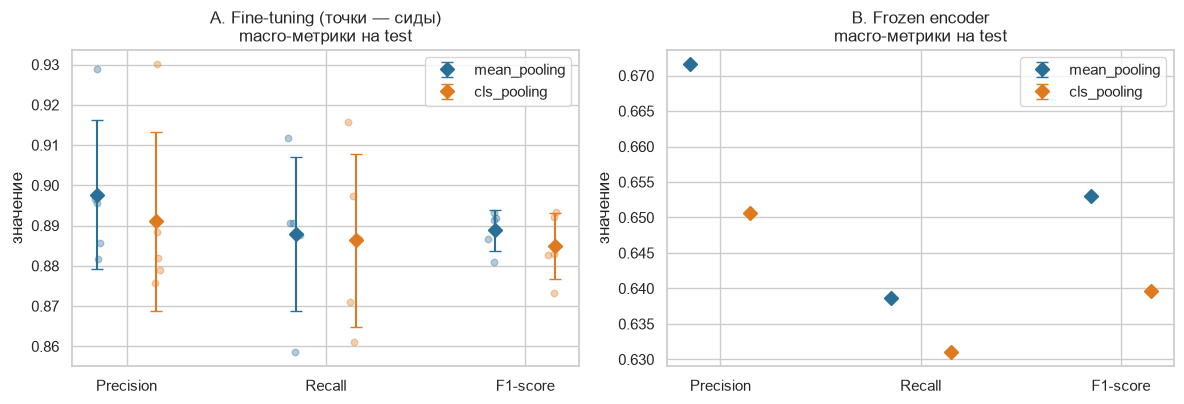

In [ ]:
colors = {"mean": "#2a6f97", "cls": "#e07a1f"}
plot_metrics = ["precision_macro", "recall_macro", "f1_macro"]
labels = ["Precision", "Recall", "F1-score"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (mode, title) in zip(axes, [("finetune", "A. Fine-tuning (точки - сиды)"), ("frozen", "B. Frozen encoder")]):
    seeds = SEEDS if mode == "finetune" else [0]
    for j, pooling in enumerate(POOLINGS):
        offset = (j - 0.5) * 0.3
        for i, m in enumerate(plot_metrics):
            vals = np.array([get_run(mode, pooling, s)["test"][m] for s in seeds])
            ax.scatter(np.full(len(vals), i + offset) + np.random.RandomState(i).uniform(-0.04, 0.04, len(vals)),
                       vals, color=colors[pooling], alpha=0.35, s=22)
            ax.errorbar(i + offset, vals.mean(), yerr=vals.std(ddof=1) if len(vals) > 1 else 0, fmt="D",
                        color=colors[pooling], capsize=4, markersize=7, label=f"{pooling}_pooling" if i == 0 else None)
    ax.set_xticks(range(len(plot_metrics)), labels)
    ax.set_title(f"{title}\nmacro-метрики на test")
    ax.set_ylabel("значение")
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "fig1_metrics.png"), dpi=150)
plt.show()

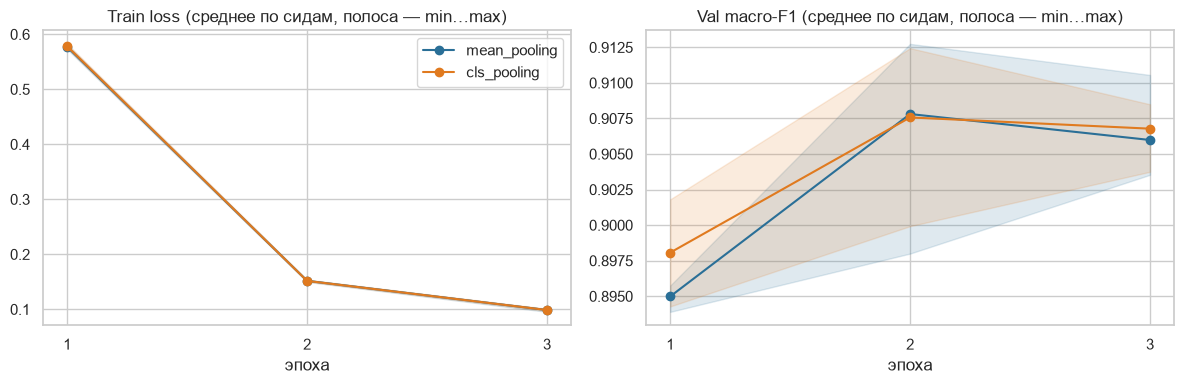

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for pooling in POOLINGS:
    for ax, key, title in [(axes[0], "train_loss", "Train loss"), (axes[1], "val_f1", "Val macro-F1")]:
        curves = np.array([[h["train_loss"] if key == "train_loss" else h["val"]["f1_macro"]
                            for h in get_run("finetune", pooling, s)["history"]] for s in SEEDS])
        x = np.arange(1, EPOCHS + 1)
        ax.plot(x, curves.mean(0), marker="o", color=colors[pooling], label=f"{pooling}_pooling")
        ax.fill_between(x, curves.min(0), curves.max(0), color=colors[pooling], alpha=0.15)
        ax.set_title(f"{title} (среднее по сидам, полоса - min…max)")
        ax.set_xlabel("эпоха")
        ax.set_xticks(x)
axes[0].legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "fig2_curves.png"), dpi=150)
plt.show()

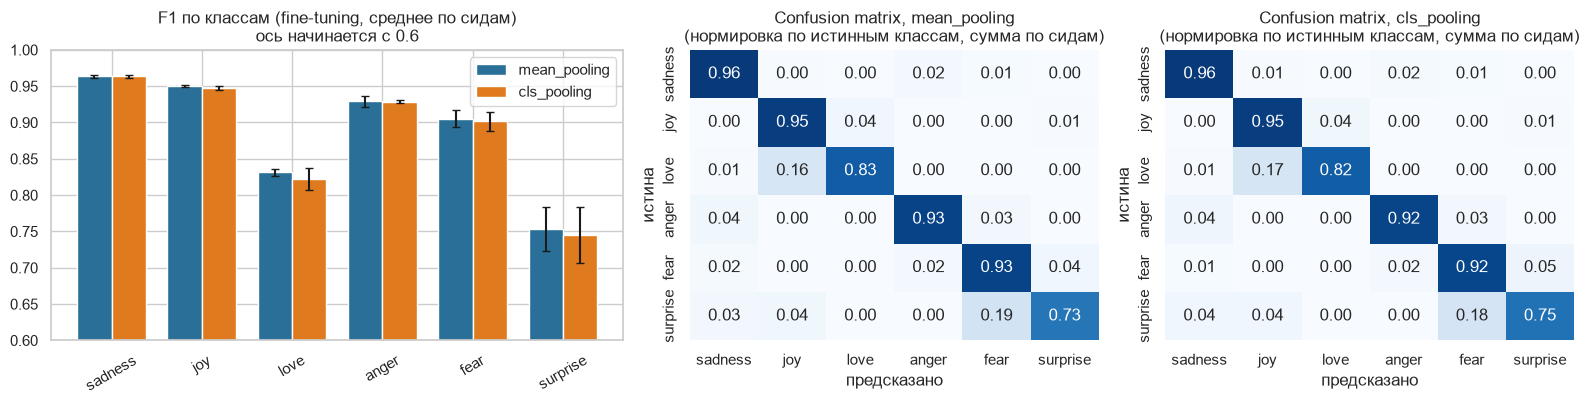

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1.4, 1, 1]})
width = 0.38
x = np.arange(N_CLASSES)
for j, pooling in enumerate(POOLINGS):
    f1s = np.array([get_run("finetune", pooling, s)["per_class"]["f1"] for s in SEEDS])
    axes[0].bar(x + (j - 0.5) * width, f1s.mean(0), width, yerr=f1s.std(0, ddof=1), capsize=3,
                color=colors[pooling], label=f"{pooling}_pooling")
axes[0].set_xticks(x, class_names, rotation=30)
axes[0].set_ylim(0.6, 1.0)
axes[0].set_title("F1 по классам (fine-tuning, среднее по сидам)\nось начинается с 0.6")
axes[0].legend()

for ax, pooling in zip(axes[1:], POOLINGS):
    cm = np.sum([get_run("finetune", pooling, s)["confusion"] for s in SEEDS], axis=0)
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f"Confusion matrix, {pooling}_pooling\n(нормировка по истинным классам, сумма по сидам)")
    ax.set_xlabel("предсказано")
    ax.set_ylabel("истина")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "fig3_per_class.png"), dpi=150)
plt.show()

## Выводы

**Данные:** `dair-ai/emotion` (6 классов), модель `BAAI/bge-small-en-v1.5`, test-выборка 2 000 примеров.
Fine-tuning - 5 сидов, 3 эпохи, лучшая эпоха выбрана по val macro-F1.

| | mean_pooling | cls_pooling | Δ (cls − mean) | p-value |
|---|---|---|---|---|
| **Fine-tuning**, Precision (macro) | 0.8977 ± 0.0186 | 0.8910 ± 0.0223 | −0.0067 | 0.16 |
| **Fine-tuning**, Recall (macro) | 0.8879 ± 0.0190 | 0.8863 ± 0.0216 | −0.0016 | 0.75 |
| **Fine-tuning**, F1 (macro) | 0.8888 ± 0.0050 | 0.8848 ± 0.0082 | −0.0039 | 0.39 |
| Fine-tuning, Accuracy | 0.9304 ± 0.0010 | 0.9281 ± 0.0035 | −0.0023 | 0.28 |
| Frozen encoder, Precision (macro) | 0.6716 | 0.6506 | −0.0210 | - |
| Frozen encoder, Recall (macro) | 0.6386 | 0.6310 | −0.0076 | - |
| Frozen encoder, F1 (macro) | 0.6530 | 0.6396 | −0.0133 | - |

**1. При fine-tuning статистически значимой разницы между пулингами нет.**
`mean_pooling` в среднем чуть выше по всем метрикам (F1: 0.889 против 0.885), но разница (0.004) меньше разброса между сидами (std 0.005–0.008), по F1 `cls` выигрывает на 3 сидах из 5, парный t-тест даёт p = 0.16–0.75. С пятью сидами тест маломощный, поэтому корректная формулировка: *различие, если оно есть, меньше ~1 п.п.*, и на нашей выборке мы его не обнаружили. Ни в одной метрике нельзя сказать, что одна стратегия лучше.

**2. Без дообучения (frozen encoder) качество намного ниже** (macro-F1 ≈ 0.65 против ≈ 0.89): эмбеддинги общего назначения плохо разделяют эмоции линейным классификатором, а дообучение энкодера даёт примерно +24 п.п. macro-F1.
Здесь `mean_pooling` тоже впереди (F1 0.653 против 0.640, Δ = 0.013), направление совпадает с fine-tuning, но это один детерминированный запуск на каждый пулинг, оценки разброса нет, а при 2 000 тестовых примеров разница в ≈1 п.п. сама может быть шумом выборки.

**3. Ошибки одинаковые у обоих пулингов.** Самые трудные классы - `surprise` (F1 ≈ 0.75) и `love` (≈ 0.82–0.83): `love` путается с `joy` (16–17 % примеров), `surprise` - с `fear` (18–19 %). Это следствие дисбаланса и семантической близости классов, а не выбора пулинга: по классам различия между `mean` и `cls` лежат в пределах столбиков ошибок.

**Возможные объяснения (гипотезы, которые в этой работе не проверялись):**
* при fine-tuning весь энкодер подстраивается под выбранный способ агрегации, поэтому исходное «предпочтение» модели к CLS она обучалась с CLS-пулингом за три эпохи нивелируется;
* у замороженной модели вектор `[CLS]` оптимизирован под поиск похожих текстов, а усреднение использует информацию со всех токенов, что может быть полезнее для распознавания эмоционально окрашенных слов.

**Ограничения:** один датасет, одна модель, один набор гиперпараметров и 3 эпохи; для более уверенного вывода
нужны другие датасеты/модели (в частности, модель, обученная с mean-пулингом, например `e5`) и больше сидов.